Import Packages and Useful Function

In [1]:
import pandas as pd
from labtools.adtools import sort
import seaborn as sns
import matplotlib.pyplot as plt
# Function for writing dictionary to csv file (used for loss tables)
import csv
def write_dict_to_csv(file_path, dictionary):
    with open(file_path, 'w', newline='') as csvfile:
        writer = csv.writer(csvfile)
        writer.writerow(dictionary.keys())
        writer.writerow(dictionary.values())
dir = '/global/scratch/projects/fc_mvslab/OpenProjects/Marissa/SynADs/2024-04-00_w.labtoolsDev/2025-10-14_Reprocess/'
name = 'SynAD_mCherry'

Initialize the sort

In [2]:
my_sort = sort.Sort(["/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Apr2024/20240425/MZ_SynADs/results/R1_S21.fastq.gz.assembled.fastq",
                    "/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Apr2024/20240425/MZ_SynADs/results/R2_S22.fastq.gz.assembled.fastq",
                    "/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Apr2024/20240425/MZ_SynADs/results/R3_S23.fastq.gz.assembled.fastq",
                    "/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Apr2024/20240425/MZ_SynADs/results/R4_S24.fastq.gz.assembled.fastq"], 
                    bin_counts = [1200000,1200000,1200000,1000000], 
                    bin_values = [28,165,299,517], 
                    design_file = "/global/scratch/projects/fc_mvslab/OpenProjects/Marissa/DesignFiles/PlantSynADs_Design.csv")

Process

In [3]:
activities, total_reads, reads_per_bin, loss_table = my_sort.process(thresh=39, ad_preceder = "GCTAGC", bc_preceder = "GGGCCCG", 
            bc_anteceder = "GGCGCGCC", ad_length = 120, bclength = 14, barcoded = True)

Opening file R1_S21.fastq.gz.assembled.fastq ...
Total parsed reads = 14,604,453                      
Opening file R2_S22.fastq.gz.assembled.fastq ...
Total parsed reads = 12,496,710                      
Opening file R3_S23.fastq.gz.assembled.fastq ...
Total parsed reads = 13,281,658                      
Opening file R4_S24.fastq.gz.assembled.fastq ...
Total parsed reads = 17,680,750                      


Outputs

In [4]:
loss_table

{'ad_preceder': 238423,
 'design_file': 3691587.0,
 'thresh': 453215.0,
 'bc_is_na': 4542.0,
 'bc_flanks': 182541,
 'bc_length': 55041}

In [5]:
# Convert Series of tuples to DataFrame with two columns
total_reads_df = total_reads.apply(pd.Series)
# Reset index to convert the tuple index into columns
total_reads_df = total_reads.reset_index()
# Rename the columns
total_reads_df.columns = ['AD', 'BC', 'Reads']
# Count the occurrences of each 'BC' and create a new Series
bc_counts = total_reads_df['BC'].value_counts()
# Assign the counts back to the original DataFrame
total_reads_df['ADs_per_BC'] = total_reads_df['BC'].map(bc_counts)
# Similarly, count the occurrences of each 'AD' and create a new Series
ad_counts = total_reads_df['AD'].value_counts()
# Assign the counts back to the original DataFrame
total_reads_df['BCs_per_AD'] = total_reads_df['AD'].map(ad_counts)
# Sum all the reads that have the same sequence in the 'AD' column
total_reads_df['numreads_per_AD'] = total_reads_df.groupby('AD')['Reads'].transform('sum')

activities.reset_index(inplace=True)
# Rename the columns for clarity
activities.rename(columns={'level_0': 'DNAseq', 'level_1': 'BC'}, inplace=True)
activities

,DNAseq,BC,0,1,2,3,Activity
0,AAATCTGATACTACTATGGAAGAAGATGAAGATGGTGATGTTTCTT...,TTGATTACCTATGA,0.412896,0.330776,0.203256,0.053071,154.350678
1,ATTGATTTGTCTAGATTGAATGGTTATGATCAATTGATTTTGGAAT...,ATCTATCTAGCAGA,0.551437,0.236369,0.107016,0.105178,140.815736
2,AAATCTAAATGTGAAAATATTGATCATTTGTTTTCTACTAGAGCTG...,AGAAACCCCCGAAC,0.519141,0.287000,0.149230,0.044629,129.583752
3,CCAGAAGAAGAAACTAAAGCTGCTGAACCAAATTATGGTTCTGTTG...,CAGCACAGTGTGTA,0.082315,0.127908,0.020743,0.769033,427.201933
4,ATTTCTCCATTTTCTGATATGTTGATTGATGATCAACCATGGTCTT...,CCCTGTACCTAAAA,0.360716,0.299240,0.197162,0.142882,192.296193
...,...,...,...,...,...,...,...
45200,TTTAATTTTCCACATTTGTTGACTACTTCTTTGTCTGATGATTTTA...,TGCTATTAAAGGAG,0.000000,0.000000,0.000000,1.000000,517.000000
45201,GGTGTTCCAGAATTGGCTTCTTTGGCTGGTTTGAATCCAATTCCAG...,ACTTGACTTATTAT,0.000000,0.000000,0.000000,1.000000,517.000000
45202,GATTCTATTCCATTGGATTCTAAACATTCTCAAGCTCCAAATGTTG...,TATGAAATAAGGAT,0.000000,0.000000,0.000000,1.000000,517.000000
45203,GATTCTCAAGAAATTGATGATATTAATGATTATTCTTTGACTTCTT...,AAAGAATACTATTA,0.000000,0.000000,0.000000,1.000000,517.000000


QC Analyses

In [6]:
print(total_reads_df.shape, activities.shape)

(45205, 6) (45205, 7)


In [7]:
activities.head(10)

,DNAseq,BC,0,1,2,3,Activity
0,AAATCTGATACTACTATGGAAGAAGATGAAGATGGTGATGTTTCTT...,TTGATTACCTATGA,0.412896,0.330776,0.203256,0.053071,154.350678
1,ATTGATTTGTCTAGATTGAATGGTTATGATCAATTGATTTTGGAAT...,ATCTATCTAGCAGA,0.551437,0.236369,0.107016,0.105178,140.815736
2,AAATCTAAATGTGAAAATATTGATCATTTGTTTTCTACTAGAGCTG...,AGAAACCCCCGAAC,0.519141,0.287000,0.149230,0.044629,129.583752
3,CCAGAAGAAGAAACTAAAGCTGCTGAACCAAATTATGGTTCTGTTG...,CAGCACAGTGTGTA,0.082315,0.127908,0.020743,0.769033,427.201933
4,ATTTCTCCATTTTCTGATATGTTGATTGATGATCAACCATGGTCTT...,CCCTGTACCTAAAA,0.360716,0.299240,0.197162,0.142882,192.296193
5,GCTTATAATCCATTTTCTTCTTCTCCATTGTCTGATTTGACTTTTG...,TCAAGTTCTCCGCA,0.634902,0.258255,0.095455,0.011388,94.818008
6,TCTAATACTAATACTACTACTACTCCAATTCCAGATTTGTTGTCTT...,CCGACTTTAACGGT,0.481382,0.326884,0.146198,0.045536,134.669959
7,AATTGGTTTCCAATTTTGGATTATGAATCTATTGTTATTGATGATG...,TACGTAAGCATCTA,0.448844,0.298952,0.223179,0.029024,143.630926
8,CCAGATTTTACTAAAGTTAAAGGTGAACATTCTATGATGGAACCAT...,GTTGGGCAATAATA,0.621260,0.261490,0.086156,0.031093,102.377212
9,TTGTTGTTGGATTTGTCTGATATTTCTTTGCATGATATTGCTGAAT...,GTTACGAATTAATT,0.509160,0.340759,0.150081,0.000000,115.355947


In [8]:
total_reads_df.head(10)

,AD,BC,Reads,ADs_per_BC,BCs_per_AD,numreads_per_AD
0,AAATCTGATACTACTATGGAAGAAGATGAAGATGGTGATGTTTCTT...,TTGATTACCTATGA,6178.0,1.0,6,10690.0
1,ATTGATTTGTCTAGATTGAATGGTTATGATCAATTGATTTTGGAAT...,ATCTATCTAGCAGA,3562.0,1.0,5,7236.0
2,AAATCTAAATGTGAAAATATTGATCATTTGTTTTCTACTAGAGCTG...,AGAAACCCCCGAAC,2944.0,1.0,2,4887.0
3,CCAGAAGAAGAAACTAAAGCTGCTGAACCAAATTATGGTTCTGTTG...,CAGCACAGTGTGTA,1621.0,1.0,4,4115.0
4,ATTTCTCCATTTTCTGATATGTTGATTGATGATCAACCATGGTCTT...,CCCTGTACCTAAAA,1421.0,1.0,2,5246.0
5,GCTTATAATCCATTTTCTTCTTCTCCATTGTCTGATTTGACTTTTG...,TCAAGTTCTCCGCA,7611.0,1.0,2,7880.0
6,TCTAATACTAATACTACTACTACTCCAATTCCAGATTTGTTGTCTT...,CCGACTTTAACGGT,2688.0,1.0,6,8685.0
7,AATTGGTTTCCAATTTTGGATTATGAATCTATTGTTATTGATGATG...,TACGTAAGCATCTA,4459.0,1.0,4,9271.0
8,CCAGATTTTACTAAAGTTAAAGGTGAACATTCTATGATGGAACCAT...,GTTGGGCAATAATA,3660.0,1.0,3,4181.0
9,TTGTTGTTGGATTTGTCTGATATTTCTTTGCATGATATTGCTGAAT...,GTTACGAATTAATT,3662.0,1.0,4,5131.0


In [9]:
print('sum included reads: ', total_reads_df['Reads'].sum())
total_sum = total_reads_df['Reads'].sum() + loss_table['ad_preceder'] + loss_table['design_file'] + loss_table['thresh']
print('% included reads: ', 100*total_reads_df['Reads'].sum() / total_sum)
print('% reads lost ad_preceder: ', 100*loss_table['ad_preceder'] / total_sum)
print('% reads lost design_file: ', 100*loss_table['design_file'] / total_sum)
print('% reads lost thresh: ', 100*loss_table['thresh'] / total_sum)
total_reads

sum included reads:  53680346.0
% included reads:  92.45098962308053
% reads lost ad_preceder:  0.41062407270817014
% reads lost design_file:  6.357836654586746
% reads lost thresh:  0.7805496496245469


AAATCTGATACTACTATGGAAGAAGATGAAGATGGTGATGTTTCTTTGTCTGGTGGTTTGGAATCTAATTTTTTGGATAATTTGCAATGTATTTTGGATGAAGATTTGGTTTCTGCTGTT  TTGATTACCTATGA    6178.0
ATTGATTTGTCTAGATTGAATGGTTATGATCAATTGATTTTGGAATTGGAAGAATCTTTGGGTGATGATCAATTTATGTTTATTAATGGTGTTTCTTCTACTGTTTTGGGTCAATGGAGA  ATCTATCTAGCAGA    3562.0
AAATCTAAATGTGAAAATATTGATCATTTGTTTTCTACTAGAGCTGAAGCTAATGAAACTGATGAAGATTCTGTTCCAGAATTGTTGCAACATATGTTTTTGGAAGCTTTTATTGATTGG  AGAAACCCCCGAAC    2944.0
CCAGAAGAAGAAACTAAAGCTGCTGAACCAAATTATGGTTCTGTTGCTATTTCTTTGCCATTGGAAAGAACTATTTCTTCTCAATCTATGGAAAGATCTGGTTCTTCTTCTTCTGGTTCT  CAGCACAGTGTGTA    1621.0
ATTTCTCCATTTTCTGATATGTTGATTGATGATCAACCATGGTCTTTTTTGATGGAAAATGATTTGTTTTCTGCTTATATGAATTTGGATAAATCTAATAAAGTTTTGTTTGATGTTGAT  CCCTGTACCTAAAA    1421.0
                                                                                                                                             ...  
TTTAATTTTCCACATTTGTTGACTACTTCTTTGTCTGATGATTTTAAAGGTTTTTTTAATGATGATGATGAAAATATTTTTCCATTTTTTTCTGCTTTGGATGATTTGTTGAGAGAAT

Saving Data

In [10]:
# Make combined dataframe with: DNAseq, AAseq, total reads, readsperbin, activity
merge = activities.merge(total_reads_df, left_index=True, right_index=True)
are_columns_equal = merge['DNAseq'].equals(merge['AD'])
print('activities and reads columns are equal for AD :', are_columns_equal)
merge = merge.drop(columns=[0, 1, 2, 3, 'AD'])
reads_per_bin.index.names = ['AD', 'BC']
reads_per_bin.columns = [0, 1, 2, 3]
reads_per_bin_reset = reads_per_bin.reset_index()
merge2 = merge.merge(reads_per_bin_reset, left_index=True, right_index=True) # changed to filter on index instead of column
are_columns_equal2 = merge2['DNAseq'].equals(merge2['AD'])
print(are_columns_equal2)
merge2.drop(columns=['AD'], inplace=True)
# Translates DNA sequences (in column labelled "DNAseq") to amino acid sequences and adds those in "AAseq" column
def translate_seq(df):

    # Define the translation table
    table = {
        'ATA':'I', 'ATC':'I', 'ATT':'I', 'ATG':'M',
        'ACA':'T', 'ACC':'T', 'ACG':'T', 'ACT':'T',
        'AAC':'N', 'AAT':'N', 'AAA':'K', 'AAG':'K',
        'AGC':'S', 'AGT':'S', 'AGA':'R', 'AGG':'R',
        'CTA':'L', 'CTC':'L', 'CTG':'L', 'CTT':'L',
        'CCA':'P', 'CCC':'P', 'CCG':'P', 'CCT':'P',
        'CAC':'H', 'CAT':'H', 'CAA':'Q', 'CAG':'Q',
        'CGA':'R', 'CGC':'R', 'CGG':'R', 'CGT':'R',
        'GTA':'V', 'GTC':'V', 'GTG':'V', 'GTT':'V',
        'GCA':'A', 'GCC':'A', 'GCG':'A', 'GCT':'A',
        'GAC':'D', 'GAT':'D', 'GAA':'E', 'GAG':'E',
        'GGA':'G', 'GGC':'G', 'GGG':'G', 'GGT':'G',
        'TCA':'S', 'TCC':'S', 'TCG':'S', 'TCT':'S',
        'TTC':'F', 'TTT':'F', 'TTA':'L', 'TTG':'L',
        'TAC':'Y', 'TAT':'Y', 'TAA':'_', 'TAG':'_',
        'TGC':'C', 'TGT':'C', 'TGA':'_', 'TGG':'W',
    }

    # List to store translated protein sequences
    protein_list = []

    # Translate each DNA sequence in the list
    for dnaseq in df["DNAseq"]:
        protein = ""

        # Check if the length of the DNA sequence is divisible by 3
        if len(dnaseq) % 3 == 0:
            # Iterate over the DNA sequence in steps of 3
            for i in range(0, 119, 3):
                # Extract a codon from the DNA sequence
                codon = dnaseq[i:i + 3]
                # Lookup the amino acid corresponding to the codon and append it to the protein sequence
                protein += table.get(codon, '')

        # Append the translated protein sequence to the list
        protein_list.append(protein)
    # Add a new column to the DataFrame with the translated protein sequences
    df["AAseq"] = protein_list

    return df
merge2 = translate_seq(merge2)
merge2 = merge2.reindex(columns=['DNAseq', 'AAseq', 'BC', 'Reads', 0, 1, 2, 3, 'Activity', 'ADs_per_BC', 'BCs_per_AD', 'numreads_per_AD'])

activities and reads columns are equal for AD : True
True


In [11]:
merge2

,DNAseq,AAseq,BC,Reads,0,1,2,3,Activity,ADs_per_BC,BCs_per_AD,numreads_per_AD
0,AAATCTGATACTACTATGGAAGAAGATGAAGATGGTGATGTTTCTT...,KSDTTMEEDEDGDVSLSGGLESNFLDNLQCILDEDLVSAV,TTGATTACCTATGA,6178.0,2708.0,1879.0,1233.0,358.0,154.350678,1.0,6,10690.0
1,ATTGATTTGTCTAGATTGAATGGTTATGATCAATTGATTTTGGAAT...,IDLSRLNGYDQLILELEESLGDDQFMFINGVSSTVLGQWR,ATCTATCTAGCAGA,3562.0,2039.0,757.0,366.0,400.0,140.815736,1.0,5,7236.0
2,AAATCTAAATGTGAAAATATTGATCATTTGTTTTCTACTAGAGCTG...,KSKCENIDHLFSTRAEANETDEDSVPELLQHMFLEAFIDW,AGAAACCCCCGAAC,2944.0,1606.0,769.0,427.0,142.0,129.583752,1.0,2,4887.0
3,CCAGAAGAAGAAACTAAAGCTGCTGAACCAAATTATGGTTCTGTTG...,PEEETKAAEPNYGSVAISLPLERTISSQSMERSGSSSSGS,CAGCACAGTGTGTA,1621.0,133.0,179.0,31.0,1278.0,427.201933,1.0,4,4115.0
4,ATTTCTCCATTTTCTGATATGTTGATTGATGATCAACCATGGTCTT...,ISPFSDMLIDDQPWSFLMENDLFSAYMNLDKSNKVLFDVD,CCCTGTACCTAAAA,1421.0,540.0,388.0,273.0,220.0,192.296193,1.0,2,5246.0
...,...,...,...,...,...,...,...,...,...,...,...,...
45200,TTTAATTTTCCACATTTGTTGACTACTTCTTTGTCTGATGATTTTA...,FNFPHLLTTSLSDDFKGFFNDDDENIFPFFSALDDLLRES,TGCTATTAAAGGAG,51.0,0.0,0.0,0.0,51.0,517.000000,1.0,2,4621.0
45201,GGTGTTCCAGAATTGGCTTCTTTGGCTGGTTTGAATCCAATTCCAG...,GVPELASLAGLNPIPELLNGGGGDDNMDEFLDFSATRRGT,ACTTGACTTATTAT,48.0,0.0,0.0,0.0,48.0,517.000000,1.0,4,3084.0
45202,GATTCTATTCCATTGGATTCTAAACATTCTCAAGCTCCAAATGTTG...,DSIPLDSKHSQAPNVEEGIDHSLEEDLLYMYLDMDDKVPT,TATGAAATAAGGAT,65.0,0.0,0.0,0.0,65.0,517.000000,1.0,4,15941.0
45203,GATTCTCAAGAAATTGATGATATTAATGATTATTCTTTGACTTCTT...,DSQEIDDINDYSLTSLWGLRPDLLSTFFDSFFPTDGRNEK,AAAGAATACTATTA,46.0,0.0,0.0,0.0,46.0,517.000000,1.0,2,203.0


In [12]:
reads_per_bin.to_csv(f"{dir}/DataFiles/{name}_readsperbin.csv", index=True)
write_dict_to_csv(f'{dir}/DataFiles/{name}_loss.csv', loss_table)
merge2.to_csv(f'{dir}/DataFiles/{name}_allinfo.csv', index=True)

Graphing

/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


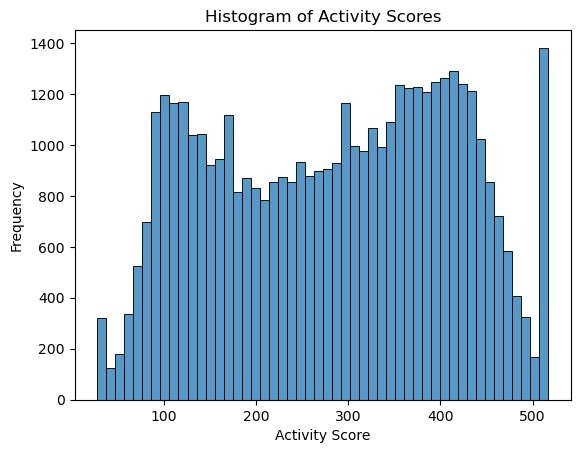

In [13]:
## Graphing Activity
sns.histplot(data=activities, x='Activity', bins=50, kde=False)
plt.xlabel('Activity Score')
plt.ylabel('Frequency')
plt.title('Histogram of Activity Scores')
plt.savefig(f'{dir}/Figs/{name}_ActivityScoreDist.jpg')
plt.show()

/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


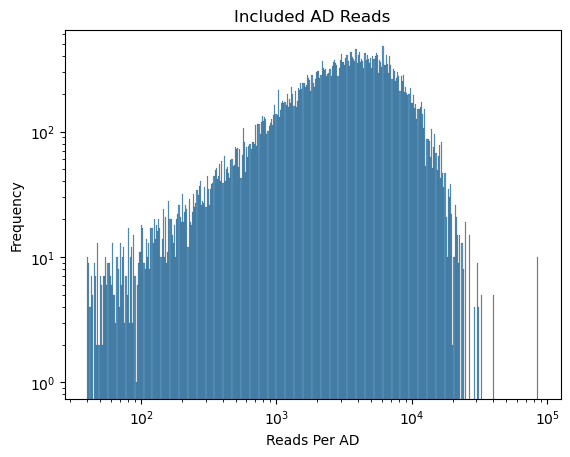

In [14]:
## Graphing AD reads

sns.histplot(data=total_reads_df, x='numreads_per_AD', bins=400, log_scale=(True, True))
plt.xlabel('Reads Per AD')
plt.ylabel('Frequency')
plt.title('Included AD Reads')
plt.savefig(f'{dir}/Figs/{name}_ADReadsDist.jpg')
plt.show()

/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


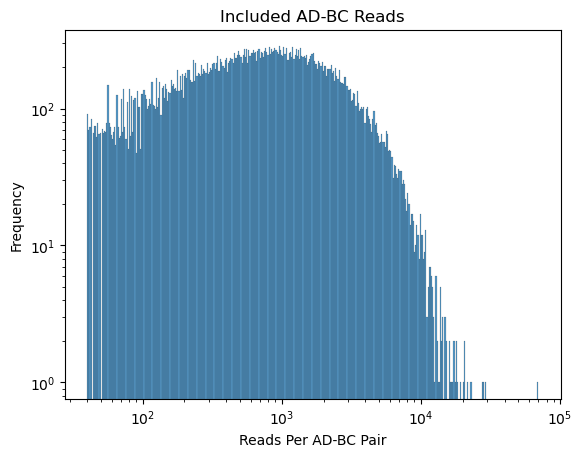

In [15]:
## Graphing AD-BC reads

sns.histplot(data=total_reads_df, x='Reads', bins=400, log_scale=(True, True))
plt.xlabel('Reads Per AD-BC Pair')
plt.ylabel('Frequency')
plt.title('Included AD-BC Reads')
plt.savefig(f'{dir}/Figs/{name}_ADBCReadsDist.jpg')
plt.show()